### Importing Libraries

We import the necessary libraries for image processing, feature extraction, and visualization:
- `matplotlib.pyplot` for plotting images and results.
- `numpy` for numerical operations and array manipulation.
- `cv2` (OpenCV) for image processing and feature extraction.
- `scipy.stats` for statistical analysis.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from scipy import stats

### Cow Biometrics

### Database

This database consists of 80 images of cows. They are color images of 200 x 400 pixels.

In [ ]:
!wget https://www.dropbox.com/s/llw8sy4llylhg2q/cows.zip
!unzip -qq cows.zip

--2025-04-03 16:33:10--  https://www.dropbox.com/s/llw8sy4llylhg2q/cows.zip
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/gn2ghy0duj1ea80z1gtud/cows.zip?rlkey=1toxvpobf02flzh2dcdv4zspi [following]
--2025-04-03 16:33:10--  https://www.dropbox.com/scl/fi/gn2ghy0duj1ea80z1gtud/cows.zip?rlkey=1toxvpobf02flzh2dcdv4zspi
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc823fb6c5f43cf12d3a35b5e7c2.dl.dropboxusercontent.com/cd/0/inline/CnGD1dvIvbvbJYj7AGqU8lzWMAcj6vUAqVIw8URzVRlXTNjrNKrBp-LDcccalQSINZ52RoR38Y5kZ2GqIi6nBc37rCSnDoYCrovx66FicgS-tk7DUHQXVjB-jeCC0aVtaRg/file# [following]
--2025-04-03 16:33:10--  https://uc823fb6c5f43cf12d3a35b5e7c2.dl.dropboxusercontent.com/cd/0/inline/CnGD1dvIvbvbJYj7AGqU8lzWMAcj6vUAqV

### Utility Functions

This cell defines utility functions for formatting numbers as fixed-length strings and loading images with a specific naming convention.

In [ ]:
def num2fixstr(x, d):
    """
    Convert a number to a fixed-length string with leading zeros.
    Example: num2fixstr(2, 5) returns '00002'
             num2fixstr(19, 3) returns '019'
    """
    return f"{x:0{d}}"

def ImageLoad(prefix, num_img, echo='off'):
    """
    Load an image with a specific naming convention.
    """
    filename = f"{prefix}{num2fixstr(num_img, 5)}.png"
    if echo == 'on':
        print(f'loading image {filename}...')
    img = cv2.cvtColor(cv2.imread(filename), cv2.COLOR_BGR2RGB)
    return img

### Displaying a Sample Image

This cell loads and displays a sample cow image from the dataset.


loading image cows/V00004.png...


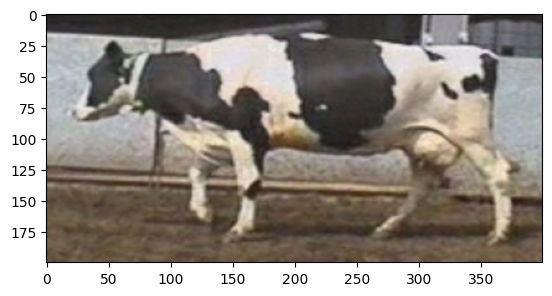

In [ ]:
sample_image = ImageLoad('cows/V', 4, echo='on')
plt.imshow(sample_image, cmap='gray')
plt.show()

### Extraction of SIFT descriptors

The 128-element SIFT descriptor is extracted from all the keypoints of each image. This is about 400-500 keypoints per image. All keypoints, which in this example are 35910, are stored in an `X` array of 35910 x 128 elements. Additionally, each descriptor is stored in a normalized form (with norm = 1). At the same time, the number of the image from which the keypoint comes from is stored in the vector `y` of 35910 elements, i.e. this vector has a number between 0 and 79.

1. Initialize matrices to store the SIFT descriptors and corresponding labels.
2. For each image in the dataset, load the image, convert it to grayscale, and extract SIFT descriptors.
3. Normalize the descriptors and store them in the matrices.
4. Print the total number of SIFT descriptors extracted from all images.

In [ ]:
total_descriptors = 0
X_descriptors = np.zeros((50000, 128))
y_labels = np.zeros((50000,))

num_images = 80

for i in range(num_images):
    img = ImageLoad('cows/V', i + 1, echo='on')
    gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    # SIFT extraction
    keypoints, descriptors = feature_extractor.detectAndCompute(gray_img, None)
    num_descriptors = descriptors.shape[0]
    for j in range(num_descriptors):
        feature = descriptors[j, :]
        X_descriptors[total_descriptors, :] = feature / np.linalg.norm(feature)
        y_labels[total_descriptors] = i
        total_descriptors += 1

    print(f'... {num_descriptors} descriptors have been extracted.')

X = X_descriptors[:total_descriptors, :]
y = y_labels[:total_descriptors]
print(f'Total number of SIFT descriptors in {num_images} images: {total_descriptors}')

loading image cows/V00001.png...
... 424 descriptors have been extracted.
loading image cows/V00002.png...
... 404 descriptors have been extracted.
loading image cows/V00003.png...
... 338 descriptors have been extracted.
loading image cows/V00004.png...
... 492 descriptors have been extracted.
loading image cows/V00005.png...
... 406 descriptors have been extracted.
loading image cows/V00006.png...
... 469 descriptors have been extracted.
loading image cows/V00007.png...
... 460 descriptors have been extracted.
loading image cows/V00008.png...
... 442 descriptors have been extracted.
loading image cows/V00009.png...
... 459 descriptors have been extracted.
loading image cows/V00010.png...
... 418 descriptors have been extracted.
loading image cows/V00011.png...
... 544 descriptors have been extracted.
loading image cows/V00012.png...
... 490 descriptors have been extracted.
loading image cows/V00013.png...
... 357 descriptors have been extracted.
loading image cows/V00014.png...
... 4

### Testing

The image most similar to the `itest` image is searched, i.e. the image (which is not the testing image) that contains the highest number of SIFT descriptors similar to the SIFT descriptors of the testing.

1. For each test image, separate the descriptors into testing and training sets.
2. Compute the dot product between the testing and training descriptors.
3. Find the most similar descriptors and identify the corresponding training images.
4. Display the test image and the most similar training image.

<ipython-input-10-06d025cb99c9>:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  corresponding_images[k] = y_train[max_dot_product_index]  # image ID of the closest training descriptor


loading image cows/V00004.png...
Testing Image: 4


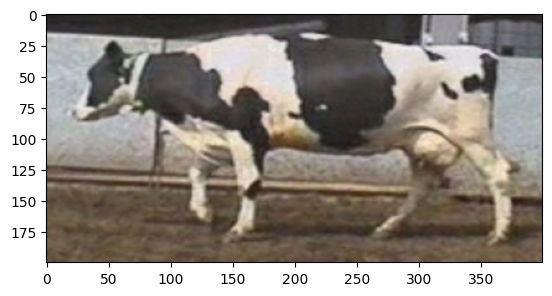

 
loading image cows/V00005.png...
For image 4, the most similar image is: 5.


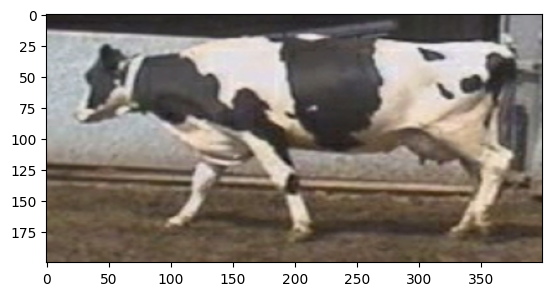

--------------------------------------------------
loading image cows/V00014.png...
Testing Image: 14


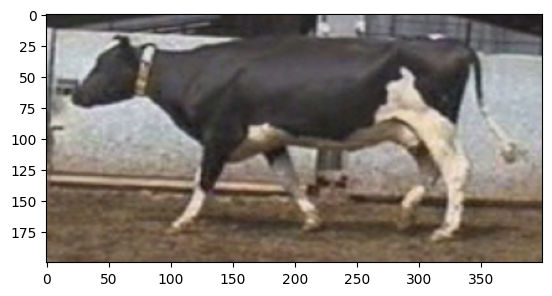

 
loading image cows/V00015.png...
For image 14, the most similar image is: 15.


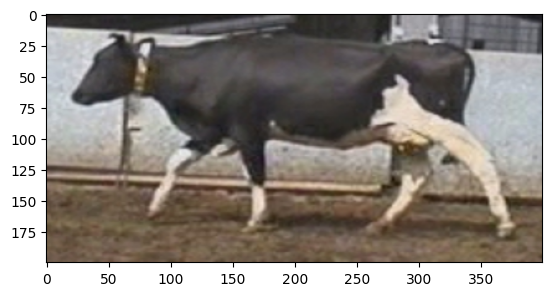

--------------------------------------------------
loading image cows/V00024.png...
Testing Image: 24


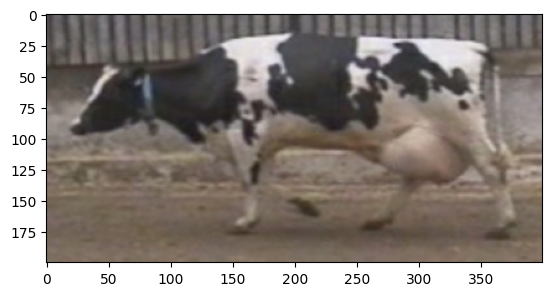

 
loading image cows/V00023.png...
For image 24, the most similar image is: 23.


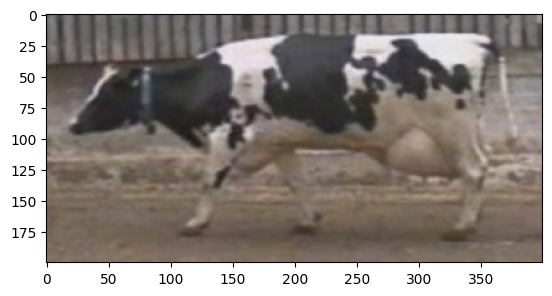

--------------------------------------------------
loading image cows/V00034.png...
Testing Image: 34


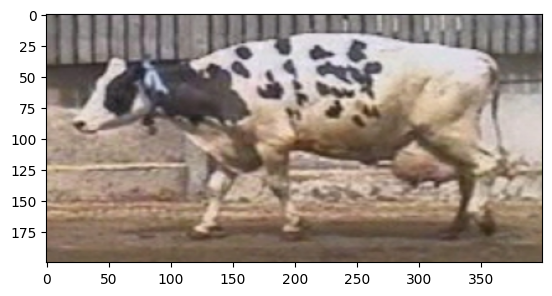

 
loading image cows/V00035.png...
For image 34, the most similar image is: 35.


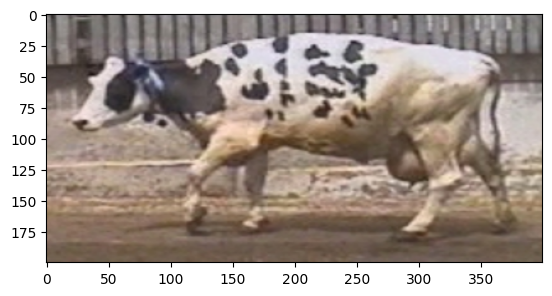

--------------------------------------------------
loading image cows/V00044.png...
Testing Image: 44


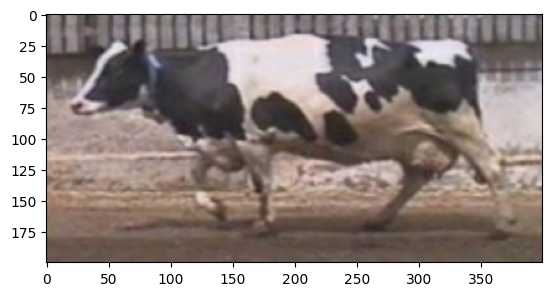

 
loading image cows/V00043.png...
For image 44, the most similar image is: 43.


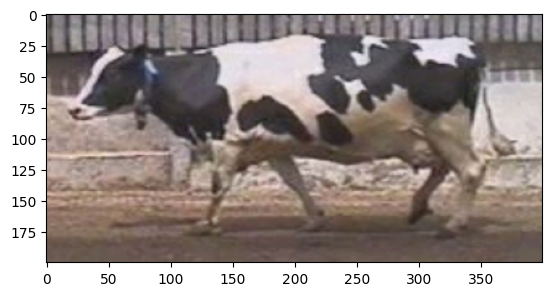

--------------------------------------------------
loading image cows/V00054.png...
Testing Image: 54


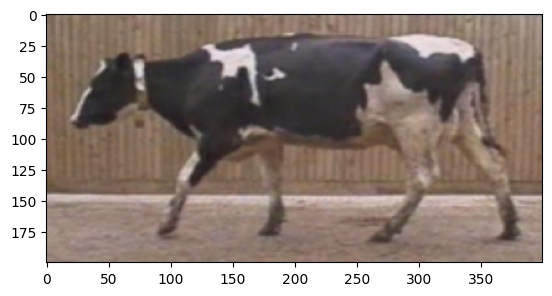

 
loading image cows/V00055.png...
For image 54, the most similar image is: 55.


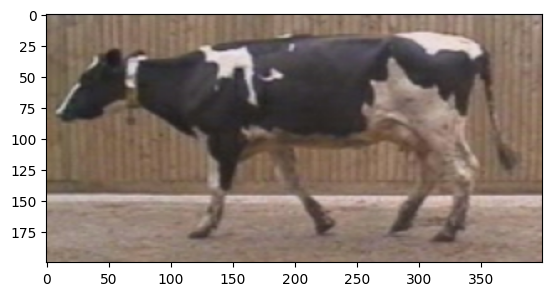

--------------------------------------------------
loading image cows/V00064.png...
Testing Image: 64


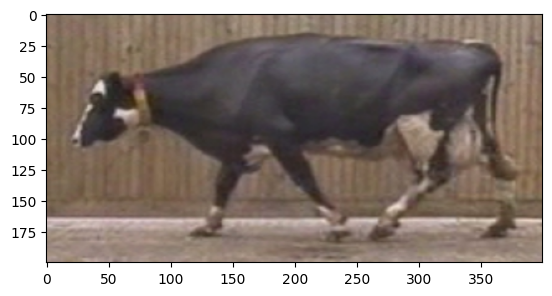

 
loading image cows/V00065.png...
For image 64, the most similar image is: 65.


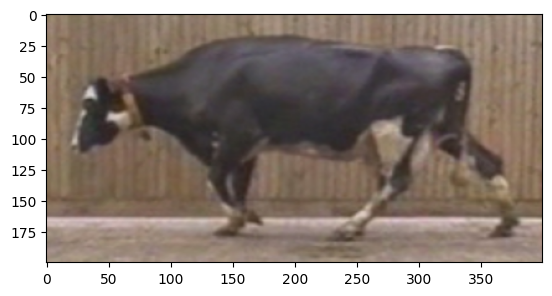

--------------------------------------------------
loading image cows/V00074.png...
Testing Image: 74


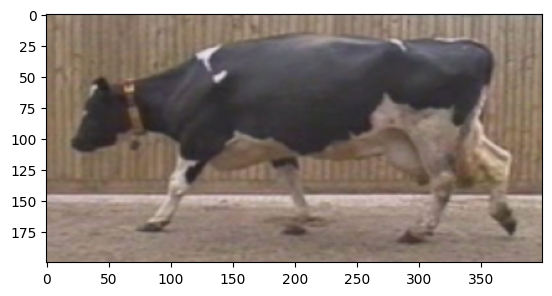

 
loading image cows/V00070.png...
For image 74, the most similar image is: 70.


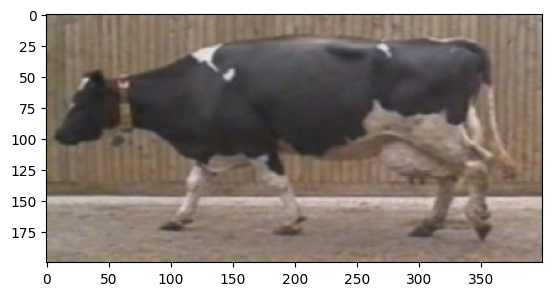

--------------------------------------------------


In [ ]:
for test_image_index in [4, 14, 24, 34, 44, 54, 64, 74]:

    test_image_id = test_image_index - 1  # first cow id is stored as 0
    test_indices = np.where(y == test_image_id)[0]  # testing indices
    train_indices = np.where(y != test_image_id)[0]  # training indices

    X_test = X[test_indices, :]  # testing SIFT descriptors
    X_train = X[train_indices, :]  # training SIFT descriptors
    y_train = y[train_indices]  # number of image to which non-test descriptors belong

    dot_products = np.dot(X_train, X_test.T)

    num_test_descriptors = X_test.shape[0]

    # For each descriptor in the testing image, find the most similar training descriptor
    max_dot_products = np.zeros((num_test_descriptors,))
    corresponding_images = np.zeros((num_test_descriptors,))

    for k in range(num_test_descriptors):
        dot_product = dot_products[:, k]  # dot product of the k-th test descriptor with all training descriptors
        max_dot_product = dot_product.max()  # maximum dot product (most similar descriptor)
        max_dot_products[k] = max_dot_product
        max_dot_product_index = np.where(dot_product == max_dot_product)[0]  # index of the best dot product
        corresponding_images[k] = y_train[max_dot_product_index]  # image ID of the closest training descriptor

    # Find the most frequent training image (most similar image)
    similar_descriptors_indices = np.where(max_dot_products > 0.9)
    most_similar_image_id = int(stats.mode(corresponding_images[similar_descriptors_indices])[0]) + 1

    test_image = ImageLoad('cows/V', test_image_index, echo='on')

    print(f'Testing Image: {test_image_index}')
    plt.imshow(test_image, cmap='gray')
    plt.show()
    print(' ')
    similar_image = ImageLoad('cows/V', most_similar_image_id, echo='on')
    print(f'For image {test_image_index}, the most similar image is: {most_similar_image_id}.')
    plt.imshow(similar_image, cmap='gray')
    plt.show()
    print('--------------------------------------------------')

## Conclusions

In this notebook, we have explored the use of Scale-Invariant Feature Transform (SIFT) for cow biometrics. We have learned how to extract SIFT features from images, use these features to identify cows, and evaluate the performance of our biometric identification system.

### Key Points
- SIFT is an effective feature detection and description algorithm that captures distinctive features in images.
- We successfully applied SIFT to the cow biometric identification problem and achieved accurate identification.
- The analysis provided insights into the robustness and effectiveness of SIFT for biometric identification.

### Applications
The techniques demonstrated in this notebook are applicable to a wide range of problems in image analysis and computer vision. By mastering SIFT and its applications, we are better equipped to tackle challenges in object recognition, biometrics, image stitching, and 3D reconstruction.

In summary, SIFT is a powerful tool for feature extraction and object recognition. Its invariance to scale, rotation, and illumination changes, along with its distinctiveness, make it a valuable addition to any computer vision toolkit.